27/10/2026

# Exercise 3 

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Integrand for luminosity distance
def f(x, om):
    return 1.0 / np.sqrt(om * np.power(1.0 + x, 3.0) + 1.0 - om)

# Luminosity distance
def dl(z, om, h0):
    return 299792.458 * (1 + z) * quad(f, 0.0, z, args=(om,))[0] / h0

# Distance modulus
def mu(z, om, h0):
    return 5.0 * np.log10(dl(z, om, h0)) + 25.0

In [6]:
# Read the observed distance modulus
zo, mo = np.loadtxt('datafile5.txt', unpack=True, skiprows=22, usecols=[2, 3])

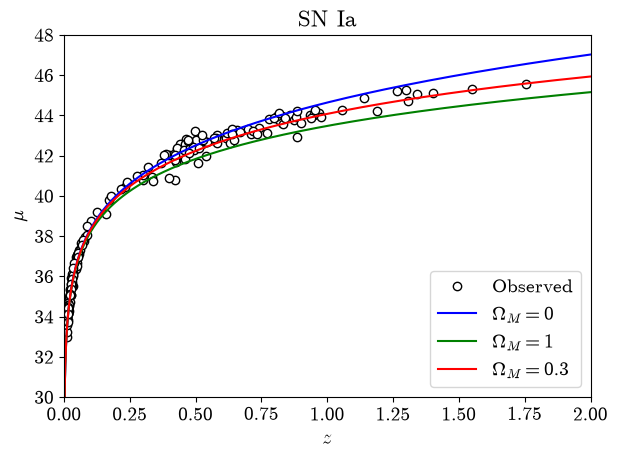

In [7]:
# Calculate the theoretical distance moduli 
zc = np.arange(0.001, 2.0, 0.001)
m1 = [mu(z, 0.0, 71.0) for z in zc] # Omega matter we changed, Hubble parameter is always the same: 71
m2 = [mu(z, 1.0, 71.0) for z in zc]
m3 = [mu(z, 0.3, 71.0) for z in zc]

# Plot the results and save the figure
plt.plot(zo, mo, 'ko', mfc='w', label='Observed') # Observations 
plt.plot(zc, m1, 'b-', label=r'$\Omega_M = 0$')
plt.plot(zc, m2, 'g-', label=r'$\Omega_M = 1$')
plt.plot(zc, m3, 'r-', label=r'$\Omega_M = 0.3$')
plt.xlim(0.0, 2.0)
plt.ylim(30.0, 48.0)
plt.xlabel('$z$')
plt.ylabel(r'$\mu$')
plt.legend(loc='lower right')
plt.title('SN Ia')
plt.tight_layout()
plt.savefig('SNIa.png', dpi=300, bbox_inches='tight')
plt.show()


**The one that fits better is Omega_M = 0.3.**